# ADSE 2026 – Preprocessing & Analisis (Team Dollar Warrior)
Self-contained notebook: all functionality is included here. Place raw files in `data/` and outputs in `output/`.

Workflow: prices → weather → weather-price correlation → risk score → risk matrix.

Run the cells from top to bottom.

In [1]:
from __future__ import annotations

from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats

## Configuration

In [2]:
DATA_DIR = Path("data")      # folder file mentah (xlsx / csv NASA POWER)
OUTPUT_DIR = Path("output")  # folder hasil

PRICE_RAW_FILE = "Harga Pangan Pasar Manado.xlsx"
PRICE_WIDE_FILE = "Harga_Pangan_Manado_PivotTable.xlsx"

DATE_FORMAT_PRICE = "%d/%m/%Y"
NASA_HEADER_ROW = 17  # jumlah baris metadata di awal file NASA POWER

COMMODITY_ALIAS = {"Cabe Rawit Merah": "CabaiRawitMerah", "Tomat": "Tomat"}
WIDE_COLUMN_ORDER = [
    "Bersehati_CabaiRawitMerah",
    "Pinasungkulan_CabaiRawitMerah",
    "Bersehati_Tomat",
    "Pinasungkulan_Tomat",
]

WEATHER_CITIES = ["Gorontalo", "Kotamobagu", "Tomohon", "Langowan"]
WEATHER_DROP_COLUMNS = ["YEAR", "DOY", "T2M_MAX"]

MAX_INTERPOLATION_GAP = 7          # hari
RAIN_LAGS = (0, 1, 2, 3)           # H0 .. H3


@dataclass(frozen=True)
class Commodity:
    """Satu komoditas gabungan dua pasar."""
    name: str                       # label di kolom hasil, mis. "Cabai"
    market_columns: tuple[str, str]  # kolom pada tabel lebar harga

    @property
    def combined_column(self) -> str:
        return f"{self.name}_Gabungan"


CABAI = Commodity("Cabai", ("Bersehati_CabaiRawitMerah", "Pinasungkulan_CabaiRawitMerah"))
TOMAT = Commodity("Tomat", ("Bersehati_Tomat", "Pinasungkulan_Tomat"))

# Pasangan (komoditas, kota sumber cuaca) yang diuji korelasinya
CORRELATION_PAIRS = [
    (CABAI, "Gorontalo"),
    (CABAI, "Kotamobagu"),
    (CABAI, "Tomohon"),
    (TOMAT, "Langowan"),
    (TOMAT, "Tomohon"),
]

# Skor risiko: bobot CRITIC dan persentil kategori
RISK_WEIGHTS = {"tren": 0.305, "cuaca": 0.335, "volatilitas": 0.359}
RISK_WINDOW = 7
RISK_PERCENTILES = {"Low": 0.50, "Medium": 0.75, "High": 0.90}  # sisanya "Critical"

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## 1. Food Prices

In [3]:
def build_price_table(raw_path: Path) -> pd.DataFrame:
    """Baca harga mentah dan ubah ke tabel lebar (indeks tanggal, kolom pasar_komoditas)."""
    df = pd.read_excel(raw_path)

    df = df.rename(columns={"Harga (/kg)": "Harga"})
    df["Tanggal"] = pd.to_datetime(df["Tanggal"], format=DATE_FORMAT_PRICE, errors="coerce")
    df["Komoditas"] = df["Komoditas"].replace(COMMODITY_ALIAS)
    df["Kolom"] = df["Pasar"] + "_" + df["Komoditas"]

    wide = df.pivot_table(index="Tanggal", columns="Kolom", values="Harga", aggfunc="mean")
    available = [c for c in WIDE_COLUMN_ORDER if c in wide.columns]
    return wide[available].sort_index()


def load_price_table(path: Path) -> pd.DataFrame:
    """Baca tabel harga lebar hasil `build_price_table` (kolom Tanggal biasa)."""
    return pd.read_excel(path, parse_dates=["Tanggal"])


def add_combined_price(prices: pd.DataFrame, commodity: Commodity) -> pd.DataFrame:
    """Rata-rata harga dua pasar (NaN diabaikan). Mengembalikan kolom Tanggal + gabungan."""
    out = prices[["Tanggal"]].copy()
    out[commodity.combined_column] = prices[list(commodity.market_columns)].mean(axis=1, skipna=True)
    return out

In [4]:
OUTPUT_DIR.mkdir(exist_ok=True)
prices = build_price_table(DATA_DIR / PRICE_RAW_FILE)
prices.to_excel(OUTPUT_DIR / PRICE_WIDE_FILE)
prices = prices.reset_index()
prices.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 283 entries, 0 to 282
Data columns (total 5 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   Tanggal                        283 non-null    datetime64[ns]
 1   Bersehati_CabaiRawitMerah      268 non-null    float64       
 2   Pinasungkulan_CabaiRawitMerah  259 non-null    float64       
 3   Bersehati_Tomat                269 non-null    float64       
 4   Pinasungkulan_Tomat            259 non-null    float64       
dtypes: datetime64[ns](1), float64(4)
memory usage: 11.2 KB


## 2. NASA POWER Weather Data

In [5]:
def preprocess_nasa_weather(raw_path: Path) -> pd.DataFrame:
    """Ubah file NASA POWER (YEAR, DOY, PRECTOTCORR, ...) menjadi Tanggal + Curah_Hujan."""
    df = pd.read_csv(raw_path, header=NASA_HEADER_ROW, sep=",", engine="python")

    df["Tanggal"] = pd.to_datetime(
        df["YEAR"].astype(str) + df["DOY"].astype(str).str.zfill(3), format="%Y%j"
    )
    df = df.drop(columns=WEATHER_DROP_COLUMNS, errors="ignore")
    return df.rename(columns={"PRECTOTCORR": "Curah_Hujan"})

In [7]:
def detect_nasa_header_row(raw_path: Path, keyword: str = "YEAR") -> int:
    """Mendeteksi baris index (0-based) di mana kata kunci header berada."""
    with open(raw_path, "r", encoding="utf-8") as f:
        for idx, line in enumerate(f):
            if keyword in line:
                return idx
    raise ValueError(f"Kata kunci '{keyword}' tidak ditemukan di file {raw_path}")

def preprocess_nasa_weather_auto(raw_path: Path) -> pd.DataFrame:
    """Ubah file NASA POWER dengan deteksi baris header otomatis."""
    header_idx = detect_nasa_header_row(raw_path)
    df = pd.read_csv(raw_path, header=header_idx, sep=",", engine="python")

    # Menghapus whitespace pada nama kolom jika ada
    df.columns = df.columns.str.strip()

    df["Tanggal"] = pd.to_datetime(
        df["YEAR"].astype(str) + df["DOY"].astype(str).str.zfill(3), format="%Y%j"
    )
    df = df.drop(columns=WEATHER_DROP_COLUMNS, errors="ignore")
    return df.rename(columns={"PRECTOTCORR": "Curah_Hujan"})

In [8]:
for city in WEATHER_CITIES:
    raw = DATA_DIR / f'Data_Cuaca_{city}.csv'
    if raw.exists():
        print(f"Memproses {city}...")
        preprocess_nasa_weather_auto(raw).to_csv(OUTPUT_DIR / f'Data_Cuaca_{city}_Preprocessed.csv', index=False)
print("Selesai memproses semua data cuaca kota!")

Memproses Gorontalo...
Memproses Kotamobagu...
Memproses Tomohon...
Memproses Langowan...
Selesai memproses semua data cuaca kota!


## 3. Weather–Price Correlation

In [11]:
def interpolate_small_gaps(series: pd.Series, max_gap: int = MAX_INTERPOLATION_GAP) -> pd.Series:
    """
    Interpolasi linear hanya untuk gap NaN sepanjang <= max_gap hari yang diapit
    dua nilai valid. Gap lebih panjang dan NaN di tepi data dibiarkan kosong.
    """
    interpolated = series.interpolate(method="linear", limit_area="inside")
    run_id = series.notna().cumsum()
    run_length = series.isna().groupby(run_id).transform("sum")
    fill_mask = series.isna() & (run_length <= max_gap)
    return series.where(~fill_mask, interpolated)


def prepare_daily_rain(weather: pd.DataFrame, lags: tuple[int, ...] = RAIN_LAGS) -> pd.DataFrame:
    """
    Rapikan hujan harian: rata-rata per tanggal, kalender lengkap, interpolasi gap kecil,
    lalu kolom lag hujan_H{n}. Kolom Status_Data menandai Aktual / Interpolasi / Missing.
    """
    rain = (
        weather.assign(Tanggal=pd.to_datetime(weather["Tanggal"], errors="coerce"))
        .groupby("Tanggal", as_index=False)["Curah_Hujan"].mean()
        .sort_values("Tanggal")
    )

    full_calendar = pd.date_range(rain["Tanggal"].min(), rain["Tanggal"].max(), freq="D")
    rain = rain.set_index("Tanggal").reindex(full_calendar).rename_axis("Tanggal")

    original = rain["Curah_Hujan"]
    rain["Curah_Hujan"] = interpolate_small_gaps(original)
    rain["Status_Data"] = np.select(
        [original.notna(), rain["Curah_Hujan"].notna()], ["Aktual", "Interpolasi"], default="Missing"
    )

    for lag in lags:
        rain[f"hujan_H{lag}"] = rain["Curah_Hujan"].shift(lag)
    return rain.reset_index()


def add_iso_week(df: pd.DataFrame) -> pd.DataFrame:
    iso = df["Tanggal"].dt.isocalendar()
    return df.assign(Tahun=iso.year, Calendar_Week=iso.week)


def build_weekly_dataset(
    prices: pd.DataFrame, daily_rain: pd.DataFrame, price_col: str
) -> pd.DataFrame:
    """Rata-ratakan harga dan hujan per ISO week, lalu gabungkan (left join pada harga)."""
    keys = ["Tahun", "Calendar_Week"]
    lag_cols = [c for c in daily_rain.columns if c.startswith("hujan_H")]

    weekly_price = add_iso_week(prices).groupby(keys, as_index=False)[price_col].mean()
    weekly_rain = add_iso_week(daily_rain).groupby(keys, as_index=False)[lag_cols].mean()

    weekly = weekly_price.merge(weekly_rain, on=keys, how="left").sort_values(keys)
    weekly["Tanggal_Minggu"] = pd.to_datetime(
        weekly["Tahun"].astype(str) + "-W" + weekly["Calendar_Week"].astype(str) + "-1",
        format="%G-W%V-%u",
        errors="coerce",
    )
    return weekly[["Tanggal_Minggu", *keys, price_col, *lag_cols]].reset_index(drop=True)


def pearson_by_lag(weekly: pd.DataFrame, price_col: str) -> pd.DataFrame:
    """Korelasi Pearson harga vs setiap lag hujan, diurutkan dari |r| terbesar."""
    rows = []
    for lag_col in [c for c in weekly.columns if c.startswith("hujan_H")]:
        pair = weekly[[price_col, lag_col]].dropna()
        r, p = stats.pearsonr(pair[price_col], pair[lag_col])
        rows.append({"lag": lag_col, "r": round(r, 3), "p_value": round(p, 4), "n": len(pair)})
    return pd.DataFrame(rows).sort_values("r", key=abs, ascending=False, ignore_index=True)


def run_weather_price_analysis(
    prices_wide: pd.DataFrame, weather_dir: Path, output_dir: Path
) -> pd.DataFrame:
    """Jalankan semua pasangan komoditas x kota. Mengembalikan tabel korelasi gabungan."""
    all_results = []
    for commodity, city in CORRELATION_PAIRS:
        price_col = commodity.combined_column
        prices = add_combined_price(prices_wide, commodity)

        weather = pd.read_csv(weather_dir / f"Data_Cuaca_{city}_Preprocessed.csv")
        daily_rain = prepare_daily_rain(weather)
        weekly = build_weekly_dataset(prices, daily_rain, price_col)

        weekly.to_csv(output_dir / f"{commodity.name}_{city}_Weekly.csv", index=False)

        result = pearson_by_lag(weekly, price_col)
        result.insert(0, "kota", city)
        result.insert(0, "komoditas", commodity.name)
        all_results.append(result)

    return pd.concat(all_results, ignore_index=True)

In [12]:
corr = run_weather_price_analysis(prices, OUTPUT_DIR, OUTPUT_DIR)
corr.to_csv(OUTPUT_DIR / 'Korelasi_Cuaca_Harga.csv', index=False)
corr

# Nama file lama (Gorontalo x cabai, mingguan) untuk kompatibilitas dengan chart SAC
pd.read_csv(OUTPUT_DIR / 'Cabai_Gorontalo_Weekly.csv').to_csv(
    OUTPUT_DIR / 'Harga_Cabai_Curah_Hujan_CalendarWeek.csv', index=False)

## 4. Oversupply Risk Score (Daily)

In [13]:
def build_daily_price_rain(
    prices_wide: pd.DataFrame, rain_city_file: Path, commodity: Commodity = CABAI
) -> pd.DataFrame:
    """Gabungkan harga gabungan harian dengan hujan harian (left join pada harga)."""
    prices = add_combined_price(prices_wide, commodity)
    daily_rain = prepare_daily_rain(pd.read_csv(rain_city_file))
    lag_cols = [c for c in daily_rain.columns if c.startswith("hujan_H")]
    merged = prices.merge(daily_rain[["Tanggal", *lag_cols]], on="Tanggal", how="left")
    return merged.sort_values("Tanggal", ignore_index=True)


def risk_thresholds(scores: pd.Series) -> dict[str, float]:
    """Batas atas tiap kategori (P50 / P75 / P90 dari distribusi skor)."""
    return {name: scores.quantile(q) for name, q in RISK_PERCENTILES.items()}


def categorize_scores(scores: pd.Series) -> pd.Series:
    """Kategori Low/Medium/High/Critical berdasarkan persentil distribusi skor."""
    thresholds = risk_thresholds(scores)

    def label(score: float) -> str | None:
        if pd.isna(score):
            return None
        for name, limit in thresholds.items():
            if score <= limit:
                return name
        return "Critical"

    return scores.map(label)


def compute_risk_score(daily: pd.DataFrame, price_col: str, rain_col: str = "hujan_H0") -> pd.DataFrame:
    """
    Komponen skor (semua dalam skala persen):
      - Tren        = (MA7 - harga) / MA7 * 100      (harga turun di bawah rata-rata = oversupply)
      - Volatilitas = StdDev7 / MA7 * 100
      - Cuaca       = min-max normalisasi hujan * 100
    Skor = bobot CRITIC x komponen; 0 jika tren negatif; tidak boleh < 0.
    """
    df = daily.sort_values("Tanggal").reset_index(drop=True).copy()

    rolling = df[price_col].rolling(window=RISK_WINDOW, min_periods=RISK_WINDOW)
    df["MA7"] = rolling.mean()
    df["StdDev7"] = rolling.std()

    df["Komponen_Tren"] = (df["MA7"] - df[price_col]) / df["MA7"] * 100
    df["Komponen_Volatilitas"] = df["StdDev7"] / df["MA7"] * 100

    rain = df[rain_col]
    df["Komponen_Cuaca"] = (rain - rain.min()) / (rain.max() - rain.min()) * 100

    weighted = (
        RISK_WEIGHTS["tren"] * df["Komponen_Tren"]
        + RISK_WEIGHTS["cuaca"] * df["Komponen_Cuaca"]
        + RISK_WEIGHTS["volatilitas"] * df["Komponen_Volatilitas"]
    )
    df["Skor_Risiko"] = weighted.where(~(df["Komponen_Tren"] < 0), 0).clip(lower=0)

    df["Kategori_Risiko"] = categorize_scores(df["Skor_Risiko"])
    df["Bulan"] = df["Tanggal"].dt.strftime("%Y-%m")  # untuk heatmap kalender di SAC
    df["Hari"] = df["Tanggal"].dt.day
    return df


RISK_OUTPUT_COLUMNS = [
    "Tanggal", "Bulan", "Hari", "Cabai_Gabungan", "hujan_H0", "MA7", "StdDev7",
    "Komponen_Tren", "Komponen_Volatilitas", "Komponen_Cuaca", "Skor_Risiko", "Kategori_Risiko",
]

In [14]:
daily = build_daily_price_rain(prices, OUTPUT_DIR / 'Data_Cuaca_Gorontalo_Preprocessed.csv')
# Data harian harga cabai + hujan Gorontalo (input chart SAC & skor risiko)
daily.to_csv(OUTPUT_DIR / 'chart4_harga_hujan_gorontalo.csv', index=False)

scored = compute_risk_score(daily, CABAI.combined_column)
scored.rename(columns={CABAI.combined_column: 'Cabai_Gabungan'})[RISK_OUTPUT_COLUMNS].to_csv(OUTPUT_DIR / 'chart5_skor_risiko.csv', index=False)
print({k: round(v, 2) for k, v in risk_thresholds(scored['Skor_Risiko']).items()})
scored['Kategori_Risiko'].value_counts()

{'Low': np.float64(0.0), 'Medium': np.float64(10.28), 'High': np.float64(16.01)}


,count
Kategori_Risiko,
Low,137
Medium,65
High,41
Critical,27


## 5. Risk Matrix Visualization

In [15]:
RISKS = [  # (id, nama, x=dampak, y=probabilitas, kategori) pada skala 0-4
    (1, "Cold storage tidak berfungsi", 2.70, 3.25, "Tinggi"),
    (2, "Korelasi cuaca-harga lemah", 3.55, 1.65, "Sedang"),
    (3, "Pencatatan stok tidak konsisten", 1.55, 2.95, "Sedang"),
    (4, "Respons birokrasi lambat", 1.95, 1.65, "Rendah"),
    (5, "Adopsi teknologi rendah", 2.70, 1.65, "Sedang"),
    (6, "Asumsi kalkulasi belum tervalidasi", 1.55, 2.65, "Sedang"),
    (7, "Kompleksitas multi-sumber pasokan", 2.70, 2.65, "Tinggi"),
    (8, "Data historis tidak terstruktur", 1.95, 1.30, "Rendah"),
]
RISK_COLORS = {"Rendah": "#70AD47", "Sedang": "#EDB64A", "Tinggi": "#C00000"}


def _draw_quadrants(ax, size, fills, labels, label_colors, label_size, label_alpha=1.0):
    """Gambar 4 kuadran (rendah, sedang kiri-atas, sedang kanan-bawah, tinggi) pada kotak size x size."""
    from matplotlib.patches import Rectangle

    mid = size / 2
    quadrants = [  # (x, y, kunci)
        (0, 0, "low"), (0, mid, "med_tl"), (mid, 0, "med_br"), (mid, mid, "high"),
    ]
    for x, y, key in quadrants:
        ax.add_patch(Rectangle((x, y), mid, mid, facecolor=fills[key], edgecolor="none", zorder=0))
        ax.text(
            x + mid / 2, y + mid / 2, labels[key], ha="center", va="center",
            fontsize=label_size, fontweight="bold", color=label_colors[key],
            alpha=label_alpha, zorder=1,
        )
    ax.axvline(mid, color="#777777", linewidth=1.3, zorder=2)
    ax.axhline(mid, color="#777777", linewidth=1.3, zorder=2)
    ax.set_xlim(0, size)
    ax.set_ylim(0, size)


def plot_risk_matrix(output_dir: Path, show: bool = False) -> None:
    """Risk matrix (probabilitas x dampak) -> PNG & PDF."""
    import matplotlib as mpl
    import matplotlib.pyplot as plt
    from matplotlib.lines import Line2D

    mpl.rcParams["font.family"] = ["Arial", "DejaVu Sans"]  # fallback otomatis
    mpl.rcParams["font.size"] = 11

    fig, ax = plt.subplots(figsize=(12, 8))
    _draw_quadrants(
        ax, size=4,
        fills={"low": "#EAF4E2", "med_tl": "#FFF3D6", "med_br": "#FFF3D6", "high": "#FBE5E5"},
        labels={"low": "RISIKO RENDAH", "med_tl": "RISIKO SEDANG",
                "med_br": "RISIKO SEDANG", "high": "RISIKO TINGGI"},
        label_colors={"low": "#548235", "med_tl": "#BF9000", "med_br": "#BF9000", "high": "#C00000"},
        label_size=12, label_alpha=0.55,
    )

    legend_handles = []
    for risk_id, name, x, y, category in RISKS:
        color = RISK_COLORS[category]
        ax.scatter(x, y, s=900, facecolor="white", edgecolor=color, linewidth=2.5, zorder=5)
        ax.text(x, y, str(risk_id), ha="center", va="center",
                fontsize=16, fontweight="bold", color=color, zorder=6)
        legend_handles.append(
            Line2D([0], [0], marker="o", color="none", markerfacecolor="white",
                   markeredgecolor=color, markeredgewidth=2, markersize=10, label=f"{risk_id}. {name}")
        )

    ax.set_xticks([0, 1, 2, 3, 4], ["Rendah", "", "", "", "Tinggi"])
    ax.set_yticks([0, 1, 2, 3, 4], ["Rendah", "", "", "", "Tinggi"])
    ax.tick_params(axis="both", length=0, colors="#444444")
    ax.set_xlabel("Tingkat Dampak", fontsize=14, fontweight="bold", labelpad=14)
    ax.set_ylabel("Probabilitas Kejadian", fontsize=14, fontweight="bold", labelpad=14)
    ax.set_title("Risk Matrix", fontsize=20, fontweight="bold", pad=20)
    ax.text(0.5, 1.01, "Pemetaan Risiko Berdasarkan Probabilitas dan Tingkat Dampak",
            transform=ax.transAxes, ha="center", va="bottom", fontsize=11, color="#666666")
    for spine in ax.spines.values():
        spine.set_color("#555555")
        spine.set_linewidth(1.2)

    ax.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(0.5, -0.17),
              ncol=2, frameon=False, fontsize=10, handletextpad=0.8, columnspacing=2.5)
    fig.text(0.5, 0.035,
             "Hijau: risiko rendah — pantau berkala   |   "
             "Kuning: risiko sedang — perlu mitigasi terencana   |   "
             "Merah: risiko tinggi — perlu perhatian segera",
             ha="center", fontsize=10, color="#555555")
    fig.subplots_adjust(left=0.12, right=0.96, top=0.88, bottom=0.32)

    for ext, kwargs in (("png", {"dpi": 300}), ("pdf", {})):
        fig.savefig(output_dir / f"risk_matrix_akademik.{ext}",
                    bbox_inches="tight", facecolor="white", **kwargs)
    if show:
        plt.show()
    plt.close(fig)


def make_sac_background(output_dir: Path, dpi: int = 200) -> Path:
    """PNG transparan 4 kuadran (skala 0-10) sebagai latar scatter chart di SAC."""
    import matplotlib.pyplot as plt
    from matplotlib.patches import Rectangle

    fig, ax = plt.subplots(figsize=(11.5, 7.2), dpi=dpi)
    _draw_quadrants(
        ax, size=10,
        fills={"low": "#e6f4ea", "med_tl": "#fdf3d7", "med_br": "#fdf3d7", "high": "#fbe4e4"},
        labels={"low": "LOW RISK", "med_tl": "MODERATE RISK",
                "med_br": "MODERATE RISK", "high": "HIGH RISK"},
        label_colors={"low": "#7a9c85", "med_tl": "#c9a227", "med_br": "#c9a227", "high": "#c0392b"},
        label_size=15,
    )
    ax.add_patch(Rectangle((0, 0), 10, 10, facecolor="none", edgecolor="#444444", linewidth=1.5, zorder=3))
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
    fig.subplots_adjust(left=0, right=1, top=1, bottom=0)
    fig.patch.set_alpha(0)

    path = output_dir / "risk_matrix_background.png"
    fig.savefig(path, dpi=dpi, transparent=True, bbox_inches=None, pad_inches=0)
    plt.close(fig)
    return path

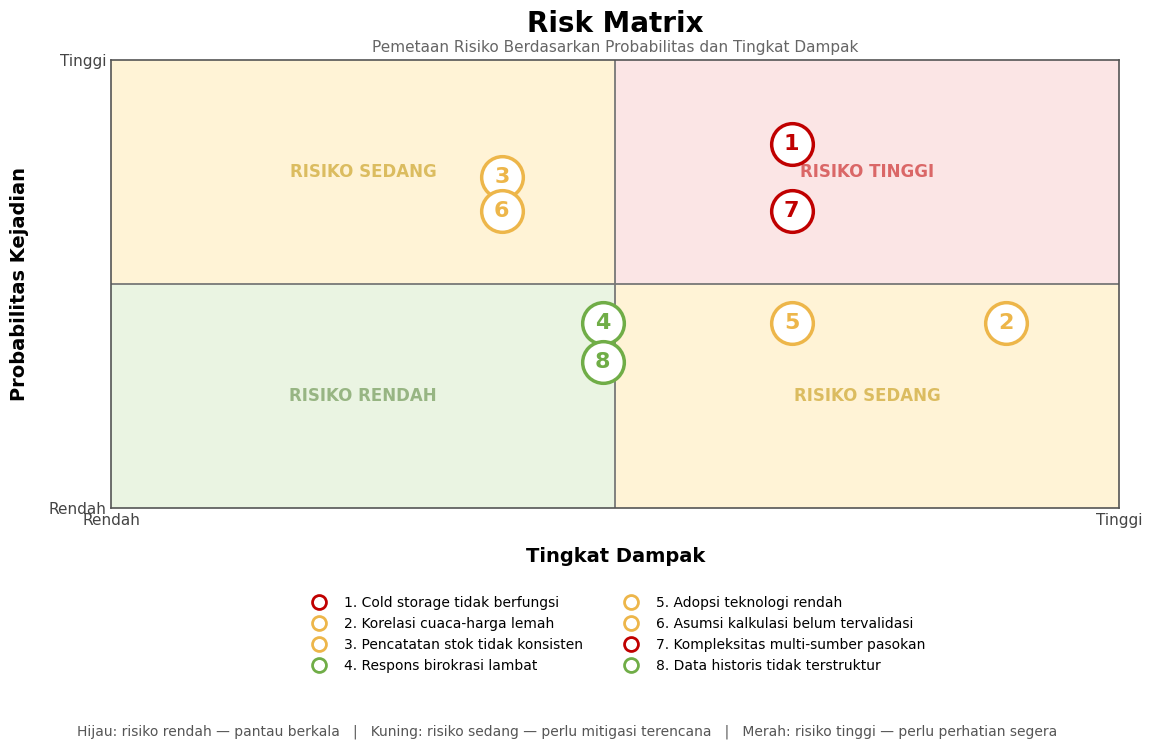

PosixPath('output/risk_matrix_background.png')

In [16]:
plot_risk_matrix(OUTPUT_DIR, show=True)
make_sac_background(OUTPUT_DIR)